# Dataset Audit

This notebook verifies the identity, structure, quality, target distribution,
column roles, categories, numerical ranges, and date validity of the assigned
employee dataset before preprocessing and modelling.

In [55]:
import pandas as pd

pd.set_option("display.max_columns", None) # Jupyter may hide some columns when you display a wide dataset.this fixes it(shows all the columns)


In [56]:
from pathlib import Path
import hashlib
import pandas as pd


# ------------------------------------------------------------
# DEFINE PROJECT PATHS
# ------------------------------------------------------------

# Find the main project folder.
# The notebook is stored inside the "notebooks" folder,
# so ".." moves one level back to the project root folder.
project_root = Path("..").resolve()


# Define the location of the raw dataset.
data_file = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)


# Define folders for saved audit results and presentation images.
results_folder = project_root / "results"
presentation_assets = project_root / "presentations" / "assets"


# Create the output folders if they do not already exist.
results_folder.mkdir(parents=True, exist_ok=True)
presentation_assets.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# VERIFY THE EXACT RAW DATASET
# ------------------------------------------------------------

# This is the approved SHA-256 checksum of the assigned raw CSV.
EXPECTED_SHA256 = (
    "2b1e07caf58e7678a780d428c1a8893a"
    "95d9c4a556134fd8e7368db5ed596cdb"
)


# Stop immediately if the expected dataset file is missing.
if not data_file.exists():
    raise FileNotFoundError(
        f"Dataset file not found:\n{data_file}"
    )


# Calculate the SHA-256 checksum of the dataset.
sha256 = hashlib.sha256()

with open(data_file, "rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha256.update(chunk)

actual_sha256 = sha256.hexdigest()


# Stop if this is not the exact approved dataset.
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError(
        "Dataset checksum does not match the approved project dataset."
    )


# ------------------------------------------------------------
# LOAD THE VERIFIED DATASET
# ------------------------------------------------------------

# Load the CSV only after its identity has been verified.
df = pd.read_csv(data_file)


# Display the resolved paths and verification result.
print("Project root:", project_root)
print("Dataset path:", data_file)
print("Results folder:", results_folder)
print("Presentation assets folder:", presentation_assets)

print("\nExpected SHA-256:", EXPECTED_SHA256)
print("Actual SHA-256:  ", actual_sha256)

print("\nDataset identity verification: PASSED")
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Project root: D:\Desktop\Employee_Resignation_Prediction
Dataset path: D:\Desktop\Employee_Resignation_Prediction\data\raw\Extended_Employee_Performance_and_Productivity_Data.csv
Results folder: D:\Desktop\Employee_Resignation_Prediction\results
Presentation assets folder: D:\Desktop\Employee_Resignation_Prediction\presentations\assets

Expected SHA-256: 2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb
Actual SHA-256:   2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb

Dataset identity verification: PASSED
Dataset loaded successfully.
Dataset shape: (100000, 20)


In [57]:
df.head() # This displays the first five rows

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False


In [58]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
# check the dataset size.This confirms that the CSV contains 100,000 employee records and 20 columns.


Rows: 100000
Columns: 20


In [59]:
for number, column in enumerate(df.columns, start=1):
    print(number, column)
# This will list all 20 columns in order

1 Employee_ID
2 Department
3 Gender
4 Age
5 Job_Title
6 Hire_Date
7 Years_At_Company
8 Education_Level
9 Performance_Score
10 Monthly_Salary
11 Work_Hours_Per_Week
12 Projects_Handled
13 Overtime_Hours
14 Sick_Days
15 Remote_Work_Frequency
16 Team_Size
17 Training_Hours
18 Promotions
19 Employee_Satisfaction_Score
20 Resigned


In [60]:
# ------------------------------------------------------------
# VERIFY THE EXACT DATASET SCHEMA
# ------------------------------------------------------------

# Define the exact column order expected in the assigned dataset.
EXPECTED_COLUMNS = [
    "Employee_ID",
    "Department",
    "Gender",
    "Age",
    "Job_Title",
    "Hire_Date",
    "Years_At_Company",
    "Education_Level",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score",
    "Resigned",
]


# Define the expected dataset dimensions.
EXPECTED_ROWS = 100_000
EXPECTED_COLUMN_COUNT = 20


# Compare the actual column order with the approved schema.
schema_matches = df.columns.tolist() == EXPECTED_COLUMNS


# Verify the number of rows.
if df.shape[0] != EXPECTED_ROWS:
    raise ValueError(
        f"Expected {EXPECTED_ROWS:,} rows, "
        f"but found {df.shape[0]:,}."
    )


# Verify the number of columns.
if df.shape[1] != EXPECTED_COLUMN_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_COLUMN_COUNT} columns, "
        f"but found {df.shape[1]}."
    )


# Verify the exact column names and order.
if not schema_matches:
    raise ValueError(
        "Dataset columns do not match the approved project schema."
    )


print("EXPECTED SCHEMA CHECK")
print("-" * 40)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("Exact column names and order:", schema_matches)

print("\nDataset schema verification: PASSED")

EXPECTED SCHEMA CHECK
----------------------------------------
Rows: 100,000
Columns: 20
Exact column names and order: True

Dataset schema verification: PASSED


In [61]:
df.info() # check each column’s data type and whether any values are missing.

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  str    
 2   Gender                       100000 non-null  str    
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  str    
 5   Hire_Date                    100000 non-null  str    
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  str    
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  Sick_Days  

In [62]:
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

# clear, saveable result confirming whether any cells are empty. just confirmation , optionl since the df.info() showed that there are no cells missing

Employee_ID                    0
Department                     0
Gender                         0
Age                            0
Job_Title                      0
Hire_Date                      0
Years_At_Company               0
Education_Level                0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
Resigned                       0
dtype: int64

Total missing values: 0


In [63]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Employee IDs:", df["Employee_ID"].duplicated().sum())
# check for duplicate rows and duplicate employee IDs.

Duplicate rows: 0
Duplicate Employee IDs: 0


In [64]:
# ------------------------------------------------------------
# VERIFY AND INSPECT THE TARGET COLUMN
# ------------------------------------------------------------

# The target must not contain missing values.
missing_target_values = df["Resigned"].isna().sum()

if missing_target_values != 0:
    raise ValueError(
        f"Resigned contains {missing_target_values} missing values."
    )


# The raw target must contain exactly the Boolean values
# False and True.
target_values = set(
    df["Resigned"]
    .dropna()
    .unique()
)

expected_target_values = {False, True}

target_values_valid = target_values == expected_target_values


# Stop if unexpected target values are present.
if not target_values_valid:
    raise ValueError(
        f"Unexpected Resigned values found: {target_values}"
    )


# Count the two target classes.
target_counts = (
    df["Resigned"]
    .value_counts()
    .sort_index()
)


# Calculate their percentages.
target_percentages = (
    df["Resigned"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)


# Display the target distribution.
print("TARGET DISTRIBUTION")
print("-" * 40)

print(f"Stayed   (False): {target_counts[False]:,}")
print(f"Resigned (True):  {target_counts[True]:,}")

print()
print(f"Stayed percentage:   {target_percentages[False]:.2f}%")
print(f"Resigned percentage: {target_percentages[True]:.2f}%")

print("\nTarget values:", target_values)
print("Target validation: PASSED")

TARGET DISTRIBUTION
----------------------------------------
Stayed   (False): 89,990
Resigned (True):  10,010

Stayed percentage:   89.99%
Resigned percentage: 10.01%

Target values: {np.False_, np.True_}
Target validation: PASSED


In [65]:
# inspect the categorical columns and their possible values, means
# Finance appears in 11,200 rows
# Marketing appears in 11,216 rows
# Engineering appears in 10,956 rows
categorical_columns = [
    "Department",
    "Gender",
    "Job_Title",
    "Education_Level"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


Department:
Department
Marketing           11216
Finance             11200
Operations          11181
IT                  11131
Sales               11122
Legal               11118
Customer Support    11116
HR                  10960
Engineering         10956
Name: count, dtype: int64

Gender:
Gender
Male      48031
Female    48001
Other      3968
Name: count, dtype: int64

Job_Title:
Job_Title
Specialist    14507
Manager       14325
Technician    14285
Analyst       14261
Engineer      14217
Consultant    14210
Developer     14195
Name: count, dtype: int64

Education_Level:
Education_Level
Bachelor       50041
High School    30004
Master         14904
PhD             5051
Name: count, dtype: int64


In [66]:
# Numerical columns used for descriptive statistics
numeric_columns = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,100000.0,41.029410,11.244121,22.0,31.00,41.0,51.00,60.0
Years_At_Company,100000.0,4.476070,2.869336,0.0,2.00,4.0,7.00,10.0
Performance_Score,100000.0,2.995430,1.414726,1.0,2.00,3.0,4.00,5.0
Monthly_Salary,100000.0,6403.211000,1372.508717,3850.0,5250.00,6500.0,7500.00,9000.0
Work_Hours_Per_Week,100000.0,44.956950,8.942003,30.0,37.00,45.0,53.00,60.0
Projects_Handled,100000.0,24.431170,14.469584,0.0,12.00,24.0,37.00,49.0
Overtime_Hours,100000.0,14.514930,8.664026,0.0,7.00,15.0,22.00,29.0
Sick_Days,100000.0,7.008550,4.331591,0.0,3.00,7.0,11.00,14.0
Remote_Work_Frequency,100000.0,50.090500,35.351157,0.0,25.00,50.0,75.00,100.0
Team_Size,100000.0,10.013560,5.495405,1.0,5.00,10.0,15.00,19.0


In [67]:
# ------------------------------------------------------------
# VERIFY HIRE_DATE
# ------------------------------------------------------------

# Parse Hire_Date as datetime values.
# errors="coerce" converts invalid values into NaT so they
# can be detected reliably.
hire_date_parsed = pd.to_datetime(
    df["Hire_Date"],
    errors="coerce"
)


# Count invalid date values.
invalid_hire_dates = hire_date_parsed.isna().sum()


# Stop if any Hire_Date value cannot be parsed.
if invalid_hire_dates != 0:
    raise ValueError(
        f"Hire_Date contains {invalid_hire_dates} invalid values."
    )


# Display the verified date range.
print("HIRE DATE VALIDATION")
print("-" * 40)

print("Invalid Hire_Date values:", invalid_hire_dates)
print("Earliest Hire_Date:", hire_date_parsed.min())
print("Latest Hire_Date:", hire_date_parsed.max())

print("\nHire_Date validation: PASSED")

HIRE DATE VALIDATION
----------------------------------------
Invalid Hire_Date values: 0
Earliest Hire_Date: 2014-09-07 08:03:05.556036
Latest Hire_Date: 2024-09-03 08:03:05.556036

Hire_Date validation: PASSED


In [68]:
# ------------------------------------------------------------
# CHECK HIRE_DATE CONSTRUCTION PATTERNS
# ------------------------------------------------------------

# Count the number of distinct time-of-day values contained
# inside Hire_Date.
unique_hire_times = hire_date_parsed.dt.time.nunique()


# Display the most common time component.
hire_time_counts = hire_date_parsed.dt.time.value_counts()


# Use the latest Hire_Date in the dataset as a reference point.
# This lets us estimate tenure from Hire_Date for comparison with
# Years_At_Company.
tenure_anchor_date = hire_date_parsed.max()


# Estimate whole years of tenure from Hire_Date.
# This is only a diagnostic comparison, not a model feature.
derived_tenure = (
    (tenure_anchor_date - hire_date_parsed).dt.days
    / 365.25
).astype(int)


# Count exact matches with the provided Years_At_Company column.
tenure_exact_matches = (
    derived_tenure == df["Years_At_Company"]
).sum()


# Also check whether every record is within one year.
tenure_within_one_year = (
    (
        derived_tenure
        - df["Years_At_Company"]
    ).abs()
    <= 1
).sum()


print("HIRE_DATE CONSTRUCTION CHECK")
print("-" * 45)

print("Unique time components:", unique_hire_times)

if len(hire_time_counts) > 0:
    print(
        "Most common time component:",
        hire_time_counts.index[0]
    )
    print(
        "Records with that time component:",
        f"{hire_time_counts.iloc[0]:,}"
    )

print()
print(
    "Exact derived-tenure matches:",
    f"{tenure_exact_matches:,} / {len(df):,}"
)

print(
    "Within one year:",
    f"{tenure_within_one_year:,} / {len(df):,}"
)


print(
    "\nThese checks are descriptive audit findings only. "
    "Raw Hire_Date remains excluded from primary modelling."
)

HIRE_DATE CONSTRUCTION CHECK
---------------------------------------------
Unique time components: 1
Most common time component: 08:03:05.556036
Records with that time component: 100,000

Exact derived-tenure matches: 99,283 / 100,000
Within one year: 100,000 / 100,000

These checks are descriptive audit findings only. Raw Hire_Date remains excluded from primary modelling.


In [69]:
# Store the identifier column separately.
# Employee_ID uniquely identifies each record, but it should not be used to train the model.
identifier_columns = ["Employee_ID"]


# Store the categorical input columns.
# These are categorical predictors, but they will NOT all use
# one universal encoding method. Their representation will be
# handled later by each model-specific preprocessing pipeline.
categorical_columns = [
    "Department",
    "Gender",
    "Job_Title",
    "Education_Level"
]


# Store the numerical input columns.
# These columns contain numbers that can be used as model features.
numerical_columns = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score"
]


# Store columns used only for checking and understanding the dataset.
# Hire_Date is inspected for data quality, but the raw value will not be used in the main model.
audit_only_columns = ["Hire_Date"]


# Store the target column.
# This is the output that the machine-learning model will try to predict.
target_column = "Resigned"


# Display the assigned role of each group of columns.
print("Identifier:", identifier_columns)
print("Categorical inputs:", categorical_columns)
print("Numerical inputs:", numerical_columns)
print("Audit-only column:", audit_only_columns)
print("Target/output:", target_column)

Identifier: ['Employee_ID']
Categorical inputs: ['Department', 'Gender', 'Job_Title', 'Education_Level']
Numerical inputs: ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
Audit-only column: ['Hire_Date']
Target/output: Resigned


In [70]:
# ------------------------------------------------------------
# CHECK MONTHLY_SALARY STRUCTURE
# ------------------------------------------------------------

# Count the number of distinct salary values in the dataset.
salary_unique_values = df["Monthly_Salary"].nunique()


# For every Job_Title + Performance_Score combination,
# count how many different salary values occur.
salary_values_per_combination = (
    df.groupby(
        ["Job_Title", "Performance_Score"]
    )["Monthly_Salary"]
    .nunique()
)


# Count the number of observed Job_Title + Performance_Score
# combinations.
salary_combination_count = len(
    salary_values_per_combination
)


# Find the maximum number of salary values associated with any
# one Job_Title + Performance_Score combination.
max_salaries_per_combo = (
    salary_values_per_combination.max()
)


# If this value is 1, every observed Job_Title +
# Performance_Score combination maps to exactly one salary.
salary_is_deterministic = (
    max_salaries_per_combo == 1
)


print("MONTHLY SALARY STRUCTURE CHECK")
print("-" * 45)

print(
    "Distinct Monthly_Salary values:",
    salary_unique_values
)

print(
    "Observed Job_Title + Performance_Score combinations:",
    salary_combination_count
)

print(
    "Maximum salary values per combination:",
    max_salaries_per_combo
)

print(
    "Salary determined by Job_Title + Performance_Score:",
    salary_is_deterministic
)

MONTHLY SALARY STRUCTURE CHECK
---------------------------------------------
Distinct Monthly_Salary values: 28
Observed Job_Title + Performance_Score combinations: 35
Maximum salary values per combination: 1
Salary determined by Job_Title + Performance_Score: True


In [71]:
# ------------------------------------------------------------
# CHECK IMPLIED EMPLOYMENT START AGE
# ------------------------------------------------------------

# Estimate the employee's age when they joined the company.
#
# This is only an approximate audit diagnostic because both
# Age and Years_At_Company are recorded as whole years.
implied_start_age = (
    df["Age"]
    - df["Years_At_Company"]
)


# Count records implying an employment start age below 18.
below_18_count = (
    implied_start_age < 18
).sum()


# Count records implying an employment start age below 16.
below_16_count = (
    implied_start_age < 16
).sum()


print("IMPLIED EMPLOYMENT START AGE CHECK")
print("-" * 45)

print(
    "Records implying start age below 18:",
    f"{below_18_count:,}"
)

print(
    "Records implying start age below 16:",
    f"{below_16_count:,}"
)

print()
print(
    "These values are treated as a dataset-quality limitation, "
    "not as evidence about real employees."
)

IMPLIED EMPLOYMENT START AGE CHECK
---------------------------------------------
Records implying start age below 18: 3,784
Records implying start age below 16: 1,503

These values are treated as a dataset-quality limitation, not as evidence about real employees.


In [72]:
# Combine the categorical and numerical columns to create the model input list.
input_columns = categorical_columns + numerical_columns

# X contains the input features the model will use.
X = df[input_columns]

# y contains the target/output the model will try to predict.
y = df[target_column]

# Display the shapes to confirm the inputs and output were created correctly.
print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (100000, 17)
Target data shape: (100000,)


In [73]:
# Display the 17 input columns selected for the model.
print("Input columns:")
for number, column in enumerate(X.columns, start=1):
    print(number, column)

# Display the name of the target/output column.
print("\nTarget column:", y.name)

Input columns:
1 Department
2 Gender
3 Job_Title
4 Education_Level
5 Age
6 Years_At_Company
7 Performance_Score
8 Monthly_Salary
9 Work_Hours_Per_Week
10 Projects_Handled
11 Overtime_Hours
12 Sick_Days
13 Remote_Work_Frequency
14 Team_Size
15 Training_Hours
16 Promotions
17 Employee_Satisfaction_Score

Target column: Resigned


In [74]:
# ------------------------------------------------------------
# CREATE AND SAVE THE MAIN AUDIT SUMMARY
# ------------------------------------------------------------

# Create one compact table containing the most important
# mechanically verified dataset-audit findings.
audit_summary = pd.DataFrame({
    "Check": [
        "Dataset SHA-256 matches approved file",
        "Number of rows",
        "Number of columns",
        "Exact schema matches",
        "Total missing values",
        "Duplicate rows",
        "Duplicate Employee IDs",
        "Target values valid",
        "Resigned = False",
        "Resigned = True",
        "Invalid Hire_Date values",
        "Unique Hire_Date time components",
        "Hire_Date-derived tenure exact matches",
        "Hire_Date-derived tenure within one year",
        "Distinct Monthly_Salary values",
        "Maximum salaries per Job_Title + Performance_Score combination",
        "Implied start age below 18",
        "Implied start age below 16",
        "Number of primary model inputs",
        "Target column",
    ],

    "Result": [
        actual_sha256 == EXPECTED_SHA256,
        df.shape[0],
        df.shape[1],
        schema_matches,
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["Employee_ID"].duplicated().sum(),
        target_values_valid,
        target_counts[False],
        target_counts[True],
        invalid_hire_dates,
        unique_hire_times,
        tenure_exact_matches,
        tenure_within_one_year,
        salary_unique_values,
        max_salaries_per_combo,
        below_18_count,
        below_16_count,
        X.shape[1],
        target_column,
    ]
})


# Display the summary in the notebook.
display(audit_summary)


# Save the summary as a reusable project result.
audit_summary_file = (
    results_folder
    / "dataset_audit_summary.csv"
)

audit_summary.to_csv(
    audit_summary_file,
    index=False
)


print(
    "\nAudit summary saved to:",
    audit_summary_file
)


,Check,Result
0,Dataset SHA-256 matches approved file,True
1,Number of rows,100000
2,Number of columns,20
3,Exact schema matches,True
4,Total missing values,0
5,Duplicate rows,0
6,Duplicate Employee IDs,0
7,Target values valid,True
8,Resigned = False,89990
9,Resigned = True,10010



Audit summary saved to: D:\Desktop\Employee_Resignation_Prediction\results\dataset_audit_summary.csv


In [75]:
# Assign a role to each dataset column.
column_roles = {
    "Employee_ID": "Identifier - excluded from model",
    "Hire_Date": "Audit-only date column",
    "Resigned": "Target/output"
}

# Add the categorical input roles.
for column in categorical_columns:
    column_roles[column] = "Categorical input"

# Add the numerical input roles.
for column in numerical_columns:
    column_roles[column] = "Numerical input"


# Create a summary table for all 20 columns.
structure_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isnull().sum().values,
    "Unique_Values": df.nunique().values,
    "Role": [column_roles[column] for column in df.columns]
})

# Display the table.
display(structure_summary)

# Save it inside the results folder.
structure_summary.to_csv(
    results_folder / "dataset_structure_summary.csv",
    index=False
)

print("Dataset structure summary saved successfully.")

,Column,Data_Type,Missing_Values,Unique_Values,Role
0,Employee_ID,int64,0,100000,Identifier - excluded from model
1,Department,str,0,9,Categorical input
2,Gender,str,0,3,Categorical input
3,Age,int64,0,39,Numerical input
4,Job_Title,str,0,7,Categorical input
5,Hire_Date,str,0,3650,Audit-only date column
6,Years_At_Company,int64,0,11,Numerical input
7,Education_Level,str,0,4,Categorical input
8,Performance_Score,int64,0,5,Numerical input
9,Monthly_Salary,float64,0,28,Numerical input


Dataset structure summary saved successfully.


In [76]:
# Create a table showing the number and percentage
# of employees in each Resigned class.

target_distribution = (
    df["Resigned"]
    .value_counts()
    .rename_axis("Resigned")
    .reset_index(name="Count")
)

# Calculate the percentage of each class.
target_distribution["Percentage"] = (
    target_distribution["Count"] / len(df) * 100
)

# Display the table.
display(target_distribution)

# Save the table in the results folder.
target_distribution.to_csv(
    results_folder / "target_distribution.csv",
    index=False
)

print("Target distribution saved successfully.")

,Resigned,Count,Percentage
0,False,89990,89.99
1,True,10010,10.01


Target distribution saved successfully.


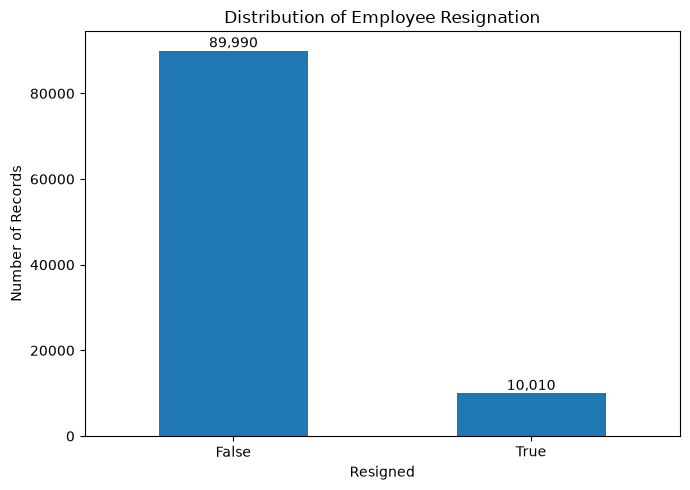

Target distribution chart saved successfully.


In [77]:
import matplotlib.pyplot as plt

# Count the False and True values in the Resigned column.
resigned_counts = df["Resigned"].value_counts().sort_index()


# Create the bar chart.
ax = resigned_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

ax.set_title("Distribution of Employee Resignation")
ax.set_xlabel("Resigned")
ax.set_ylabel("Number of Records")
ax.set_xticklabels(["False", "True"], rotation=0)


# Display the count above each bar.
for container in ax.containers:
    ax.bar_label(container, labels=[f"{value:,}" for value in resigned_counts])


plt.tight_layout()

# Save the chart as an image.
plt.savefig(
    presentation_assets / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Target distribution chart saved successfully.")

### Target Distribution Interpretation

- 89,990 records (89.99%) have `Resigned = False`.
- 10,010 records (10.01%) have `Resigned = True`.
- The target variable is therefore highly imbalanced.
- Accuracy alone may be misleading because predicting `False` for every record would already produce 89.99% accuracy.
- Imbalance-aware evaluation metrics will be required during model evaluation.

In [78]:
# Create a descriptive-statistics table for the genuine numerical columns.
numerical_summary = (
    df[numerical_columns]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "Column"})
)

# Display the summary.
display(numerical_summary)

# Save it in the results folder.
numerical_summary.to_csv(
    results_folder / "numerical_summary.csv",
    index=False
)

print("Numerical summary saved successfully.")

,Column,count,mean,std,min,25%,50%,75%,max
0,Age,100000.0,41.029410,11.244121,22.0,31.00,41.0,51.00,60.0
1,Years_At_Company,100000.0,4.476070,2.869336,0.0,2.00,4.0,7.00,10.0
2,Performance_Score,100000.0,2.995430,1.414726,1.0,2.00,3.0,4.00,5.0
3,Monthly_Salary,100000.0,6403.211000,1372.508717,3850.0,5250.00,6500.0,7500.00,9000.0
4,Work_Hours_Per_Week,100000.0,44.956950,8.942003,30.0,37.00,45.0,53.00,60.0
5,Projects_Handled,100000.0,24.431170,14.469584,0.0,12.00,24.0,37.00,49.0
6,Overtime_Hours,100000.0,14.514930,8.664026,0.0,7.00,15.0,22.00,29.0
7,Sick_Days,100000.0,7.008550,4.331591,0.0,3.00,7.0,11.00,14.0
8,Remote_Work_Frequency,100000.0,50.090500,35.351157,0.0,25.00,50.0,75.00,100.0
9,Team_Size,100000.0,10.013560,5.495405,1.0,5.00,10.0,15.00,19.0


Numerical summary saved successfully.


In [79]:
# Create one table containing the category counts
# for Department, Gender, Job_Title, and Education_Level.

categorical_summary_parts = []

for column in categorical_columns:
    column_summary = (
        df[column]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    column_summary.insert(0, "Column", column)

    column_summary["Percentage"] = (
        column_summary["Count"] / len(df) * 100
    )

    categorical_summary_parts.append(column_summary)


# Combine all categorical summaries into one table.
categorical_summary = pd.concat(
    categorical_summary_parts,
    ignore_index=True
)

# Display the complete table.
display(categorical_summary)


# Save it inside the results folder.
categorical_summary.to_csv(
    results_folder / "categorical_summary.csv",
    index=False
)

print("Categorical summary saved successfully.")

,Column,Category,Count,Percentage
0,Department,Marketing,11216,11.216
1,Department,Finance,11200,11.200
2,Department,Operations,11181,11.181
3,Department,IT,11131,11.131
4,Department,Sales,11122,11.122
5,Department,Legal,11118,11.118
6,Department,Customer Support,11116,11.116
7,Department,HR,10960,10.960
8,Department,Engineering,10956,10.956
9,Gender,Male,48031,48.031


Categorical summary saved successfully.


In [80]:
# Display every file currently saved inside the results folder.
for file in sorted(results_folder.iterdir()):
    print(file.name)

categorical_summary.csv
dataset_audit_summary.csv
dataset_structure_summary.csv
numerical_summary.csv
target_distribution.csv


In [81]:
# ------------------------------------------------------------
# FINAL DATA AUDIT VALIDATION
# ------------------------------------------------------------

# Confirm that all core structural conditions required for the
# project have passed before the audit is considered complete.

if actual_sha256 != EXPECTED_SHA256:
    raise ValueError(
        "Final audit failed: dataset checksum mismatch."
    )

if not schema_matches:
    raise ValueError(
        "Final audit failed: schema mismatch."
    )

if df.isnull().sum().sum() != 0:
    raise ValueError(
        "Final audit failed: missing values detected."
    )

if df.duplicated().sum() != 0:
    raise ValueError(
        "Final audit failed: duplicate rows detected."
    )

if df["Employee_ID"].isna().any():
    raise ValueError(
        "Final audit failed: missing Employee_ID values."
    )

if df["Employee_ID"].duplicated().any():
    raise ValueError(
        "Final audit failed: duplicate Employee_ID values."
    )

if not target_values_valid:
    raise ValueError(
        "Final audit failed: invalid target values."
    )

if invalid_hire_dates != 0:
    raise ValueError(
        "Final audit failed: invalid Hire_Date values."
    )


print("FINAL DATA AUDIT VALIDATION")
print("-" * 45)

print("Dataset identity:        PASSED")
print("Dataset schema:          PASSED")
print("Missing-value check:     PASSED")
print("Duplicate-row check:     PASSED")
print("Employee_ID check:       PASSED")
print("Target validation:       PASSED")
print("Hire_Date validation:    PASSED")

print("\nDataset audit: COMPLETE")


FINAL DATA AUDIT VALIDATION
---------------------------------------------
Dataset identity:        PASSED
Dataset schema:          PASSED
Missing-value check:     PASSED
Duplicate-row check:     PASSED
Employee_ID check:       PASSED
Target validation:       PASSED
Hire_Date validation:    PASSED

Dataset audit: COMPLETE


## Dataset Audit Conclusion

- The assigned CSV contains 100,000 rows and 20 columns.
- The SHA-256 checksum matches the approved project dataset.
- The dataset matches the expected schema and column order.
- No missing values were detected.
- No exact duplicate rows were detected.
- All `Employee_ID` values are unique.
- All `Hire_Date` values can be parsed successfully.
- All 100,000 `Hire_Date` values share the same time-of-day component, indicating a highly regular construction pattern.
- `Hire_Date` and `Years_At_Company` are strongly redundant: all records are within one year of the tenure derived from `Hire_Date`.
- `Monthly_Salary` has only 28 distinct values and is completely determined by the observed combination of `Job_Title` and `Performance_Score`.
- 3,784 records imply an employment start age below 18, including 1,503 below 16.
- These regularities are treated as dataset-quality/provenance limitations and do not establish facts about real employees.
- The target column is `Resigned`, with `True` as the positive class.
- The target is imbalanced: 10.01% `True` and 89.99% `False`.
- Seventeen columns are selected as primary model inputs.
- `Employee_ID` is excluded because it is an identifier.
- Raw `Hire_Date` is retained for auditing but excluded from primary modelling.
- The structural audit is complete. Subsequent exploratory analysis and preprocessing decisions should use the locked development partition rather than the formal holdout.